# 05a · Diagnóstico do slotting atual
**Slotting** = decidir qual SKU fica em qual endereço. No SDC, a separação de caixas (B2B) é feita
nas **faces de picking** (nível 1 do porta-palete). SKU sem face é separado direto do **pulmão**
(níveis 2–6), o que exige a empilhadeira retrátil para baixar o palete: mais lento e mais caro.

Perguntas: (1) como as faces estão distribuídas hoje? (2) quanto isso custa por ano?
(3) o putaway no pulmão segue alguma lógica?

*EN summary: current slotting diagnosis — pick faces follow SKU registration order, not velocity;
baseline annual picking/replenishment time and cost from config assumptions.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log, params, PHASE5, OUT, ZONE_COLORS

NB = "05a"
P = params()
prod, custo = P["productivity"], P["labor_cost"]
ANOS = 2.0   # 24 meses de dados -> valores anuais = total / 2
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
print("Premissas (config/parameters.yaml):", prod, custo, sep="\n")

Premissas (config/parameters.yaml):
{'walk_speed_m_s': 1.0, 'reach_truck_speed_m_s': 1.5, 'pick_time_per_line_s': 20, 'reserve_retrieval_s': 90, 'replenish_time_s': 180, 'relocation_time_s': 300, 'travel_origin': {'dry': [72.5, 25.0], 'chilled': [164.0, 20.0], 'frozen': [164.0, 20.0]}}
{'picker_brl_h': 28.0, 'reach_truck_brl_h': 45.0}


## 1. Distância de cada endereço ao ponto de partida do separador
Distância **retilínea** (|Δx| + |Δy|), porque o separador anda pelos corredores, não em linha reta.
Ida e volta por linha separada — simplificação: na prática o separador junta várias linhas numa
rota; por isso os valores servem para **comparar** cenários, não como tempo exato.

In [2]:
loc = q("SELECT location_id, location_code, zone, location_type, aisle, bay, level, x_m, y_m FROM dim_location")
origem = loc.zone.map(lambda z: P["productivity"]["travel_origin"][z])
loc["dist_m"] = (loc.x_m - origem.str[0]).abs() + (loc.y_m - origem.str[1]).abs()
faces = loc[loc.location_type == "pick"].copy()
faces.groupby("zone").dist_m.describe()[["count", "min", "50%", "max"]].round(1)

,count,min,50%,max
zone,,,,
chilled,40.0,10.5,22.7,34.8
dry,232.0,68.8,109.4,162.0
frozen,32.0,32.4,41.9,51.4


## 2. Visitas de separação por SKU
Visita = um movimento `PICK` de caixas (exclui o fracionado do e-commerce, que é feito nas
estantes de unidade). Separamos de onde saiu: face, pulmão ou transbordo.

In [3]:
mov = q("""SELECT m.sku_id, l.location_type AS origem_tipo, l.location_id,
                  COUNT(*) AS visitas, SUM(m.qty_units) AS und
           FROM fact_movement m JOIN dim_location l ON l.location_id = m.from_location_id
           WHERE m.movement_type = 'PICK' AND l.location_type <> 'unit_bin'
           GROUP BY 1, 2, 3""")
mov = mov.merge(loc[["location_id", "dist_m"]], on="location_id")

sku = q("""SELECT sku_id, sku_code, zone, status, units_per_case, cases_per_pallet,
                  pick_face_location_id, registered_date FROM dim_sku""")
sku["und_palete"] = sku.units_per_case * sku.cases_per_pallet
abc = pd.read_csv(OUT / "sku_abc_xyz.csv", sep=";", decimal=",")[["sku_id", "abc", "classe"]]
sku = sku.merge(abc, on="sku_id", how="left")

por_sku = mov.pivot_table(index="sku_id", columns="origem_tipo", values="visitas", aggfunc="sum").fillna(0)
por_sku["visitas_total"] = por_sku.sum(axis=1)
por_sku["und_total"] = mov.groupby("sku_id").und.sum()
# Distância média ao pulmão de cada SKU (de onde a retrátil baixa o palete)
pulmao = mov[mov.origem_tipo.isin(["reserve", "overflow"])]
por_sku["dist_pulmao_m"] = (pulmao.assign(p=pulmao.dist_m * pulmao.visitas).groupby("sku_id").p.sum()
                            / pulmao.groupby("sku_id").visitas.sum())
base = sku.merge(por_sku.reset_index(), on="sku_id", how="left").fillna({"visitas_total": 0, "und_total": 0})
base["visitas_ano"] = base.visitas_total / ANOS
base["paletes_ano"] = base.und_total / base.und_palete / ANOS
base["tem_face"] = base.pick_face_location_id.notna()
base = base.merge(faces[["location_id", "dist_m"]].rename(columns={"location_id": "pick_face_location_id",
                                                                    "dist_m": "dist_face_m"}),
                  on="pick_face_location_id", how="left")
# SKU sem histórico de pulmão: usa a distância média do pulmão da zona (premissa)
base["dist_pulmao_m"] = base.dist_pulmao_m.fillna(base.groupby("zone").dist_pulmao_m.transform("mean"))

resumo = base.groupby(["zone", "tem_face"]).agg(skus=("sku_id", "size"), visitas_ano=("visitas_ano", "sum"))
resumo["pct_visitas_zona"] = (100 * resumo.visitas_ano / resumo.groupby("zone").visitas_ano.transform("sum")).round(1)
resumo.round(0)

skus  visitas_ano  pct_visitas_zona
zone    tem_face                                     
chilled False       50     113356.0              61.0
        True        40      73818.0              39.0
dry     False      218     183920.0              53.0
        True       232     164130.0              47.0
frozen  False       28      33103.0              46.0
        True        32      38716.0              54.0

## 3. Qual é a regra de atribuição das faces hoje?

In [4]:
# Ordem da face (location_id) × ordem do SKU (sku_id = ordem de cadastro no sistema)
com_face = base[base.tem_face].copy()
print("Correlação de postos (Spearman) ordem da face × sku_id:",
      round(com_face.pick_face_location_id.corr(com_face.sku_id, method="spearman"), 3))
print("Correlação de postos distância da face × visitas/ano :",
      round(com_face.dist_face_m.corr(com_face.visitas_ano, method="spearman"), 3))
pd.crosstab(base.zone, [base.abc, base.tem_face], margins=True)

Correlação de postos (Spearman) ordem da face × sku_id: 1.0
Correlação de postos distância da face × visitas/ano : -0.229


abc          A          B          C       All
tem_face False True False True False True     
zone                                          
chilled     22   15    18   11    10   14   90
dry         39   26    50   63   129  143  450
frozen      10   10     7   14    11    8   60
All         71   51    75   88   150  165  600

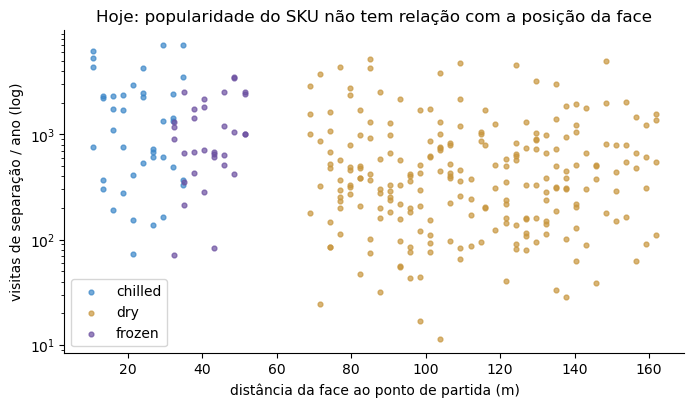

In [5]:
# Dispersão: se o slotting fosse bom, SKUs mais visitados (eixo y) estariam nas faces mais próximas (eixo x pequeno).
fig, ax = plt.subplots(figsize=(8, 4.2))
for z, g in com_face.groupby("zone"):
    ax.scatter(g.dist_face_m, g.visitas_ano, s=12, alpha=0.7, color=ZONE_COLORS[z], label=z)
ax.set_yscale("log"); ax.set_xlabel("distância da face ao ponto de partida (m)")
ax.set_ylabel("visitas de separação / ano (log)"); ax.legend()
ax.set_title("Hoje: popularidade do SKU não tem relação com a posição da face")
savefig(fig, "05a_face_dist_vs_visitas", out=PHASE5)

**Leitura:** a face de cada SKU segue exatamente a **ordem do código do SKU** (correlação = 1 com
`sku_id`) e tem relação fraca com a popularidade (−0,2). Metade dos SKUs não tem face —
inclusive **71 dos 122 itens da curva A** — e toda visita deles passa pela retrátil no pulmão.

*Nota de escala:* na escala 10% as faces do seco ficam só nas primeiras ruas (longe da expedição),
por isso as distâncias do seco são grandes. Os valores em R$ também estão na escala 10%.

## 4. Mesmo com face, parte da separação sai do pulmão
Quando a face esvazia antes do reabastecimento, o separador pega do pulmão. Isso mede a
eficácia do reabastecimento (tema da 05b).

In [6]:
com_face["pct_da_face"] = com_face["pick"] / com_face.visitas_total
com_face["faixa_giro"] = pd.qcut(com_face.paletes_ano, 4, labels=["Q1 (menor giro)", "Q2", "Q3", "Q4 (maior giro)"])
com_face.groupby("faixa_giro", observed=True).agg(skus=("sku_id", "size"),
                                                  paletes_ano_mediana=("paletes_ano", "median"),
                                                  pct_visitas_na_face=("pct_da_face", "mean")).round(2)

,skus,paletes_ano_mediana,pct_visitas_na_face
faixa_giro,,,
Q1 (menor giro),76,2.00,0.73
Q2,76,7.13,0.65
Q3,76,21.12,0.61
Q4 (maior giro),76,89.32,0.55


**Leitura:** em média só ~60% das visitas de SKUs com face são atendidas pela face; quanto maior o
giro, pior (a face de 1 palete esvazia rápido). Isso é premissa do modelo de custo e alavanca de
melhoria no reabastecimento.

## 5. Putaway no pulmão: o endereço depende do giro?
Se o putaway fosse dirigido, SKUs de giro alto ficariam no pulmão mais perto da expedição.

In [7]:
put = q("""SELECT r.sku_id, l.zone, l.level, l.x_m, l.y_m
           FROM fact_receipt r JOIN dim_location l ON l.location_id = r.putaway_location_id
           WHERE r.status = 'ACCEPTED' AND l.location_type = 'reserve'""")
origem_p = put.zone.map(lambda z: P["productivity"]["travel_origin"][z])
put["dist_m"] = (put.x_m - origem_p.str[0]).abs() + (put.y_m - origem_p.str[1]).abs()
put_sku = put.groupby(["sku_id", "zone"]).agg(dist_media=("dist_m", "mean"), nivel_medio=("level", "mean")).reset_index()
put_sku = put_sku.merge(base[["sku_id", "paletes_ano"]], on="sku_id")
for z, g in put_sku.groupby("zone"):
    print(f"{z:8s} correlação giro × distância do pulmão: {g.paletes_ano.corr(g.dist_media, method='spearman'):+.2f}"
          f" | giro × nível: {g.paletes_ano.corr(g.nivel_medio, method='spearman'):+.2f}")

chilled  correlação giro × distância do pulmão: +0.11 | giro × nível: +0.05
dry      correlação giro × distância do pulmão: +0.01 | giro × nível: +0.03
frozen   correlação giro × distância do pulmão: +0.09 | giro × nível: +0.04


**Leitura:** nenhuma relação entre giro e posição no pulmão — o palete vai para o **primeiro
endereço livre**. Itens de giro alto podem estar no fundo do galpão e no nível 6, aumentando o
tempo da retrátil a cada reabastecimento e a cada separação pelo pulmão.

## 6. Custo atual (linha de base)
Por SKU e por ano, com as premissas de `config/parameters.yaml`:
- **Visita na face:** separador anda ida e volta até a face + tempo de separação.
- **Visita no pulmão:** separador anda até a rua + separação + **retrátil** (baixar o palete:
  tempo fixo + ida e volta da retrátil).
- **Reabastecimento:** cada palete que passa pela face exige um reabastecimento da retrátil.
- A fração das visitas atendida pela face (≈60%) é a observada na seção 4, por zona.

In [8]:
frac_face = com_face.groupby("zone").apply(lambda g: g["pick"].sum() / g.visitas_total.sum(),
                                           include_groups=False).rename("frac_face")
print("Fração das visitas atendida pela face (observada):\n", frac_face.round(3))
base = base.merge(frac_face, left_on="zone", right_index=True)

v_a, v_r = prod["walk_speed_m_s"], prod["reach_truck_speed_m_s"]
t_pick, t_ret, t_rep = prod["pick_time_per_line_s"], prod["reserve_retrieval_s"], prod["replenish_time_s"]
c_p, c_r = custo["picker_brl_h"] / 3600, custo["reach_truck_brl_h"] / 3600   # R$ por segundo

# Custo de UMA visita pelo pulmão (separador + retrátil), por SKU
base["custo_visita_pulmao"] = ((2 * base.dist_pulmao_m / v_a + t_pick) * c_p
                               + (t_ret + 2 * base.dist_pulmao_m / v_r) * c_r)
# Custo de UMA visita numa face a d metros (separador)
def custo_visita_face(d):
    return (2 * d / v_a + t_pick) * c_p
# Custo de reabastecimento por palete que passa pela face (retrátil vai ao pulmão e volta)
base["custo_reab_palete"] = (t_rep + 2 * base.dist_pulmao_m / v_r) * c_r

def custo_anual(df, dist_face):
    """Custo anual de separação + reabastecimento de cada SKU dado a distância da face (NaN = sem face)."""
    tem = dist_face.notna()
    f = np.where(tem, df.frac_face, 0.0)
    return (df.visitas_ano * (f * custo_visita_face(dist_face.fillna(0)) + (1 - f) * df.custo_visita_pulmao)
            + np.where(tem, df.paletes_ano * f * df.custo_reab_palete, 0.0))

base["custo_atual_ano"] = custo_anual(base, base.dist_face_m)
linha_base = base.groupby("zone").agg(visitas_ano=("visitas_ano", "sum"), custo_ano=("custo_atual_ano", "sum"))
linha_base.loc["Total"] = linha_base.sum()
linha_base["custo_por_visita"] = linha_base.custo_ano / linha_base.visitas_ano
linha_base.round(2)

Fração das visitas atendida pela face (observada):
 zone
chilled    0.605
dry        0.553
frozen     0.483
Name: frac_face, dtype: float64


,visitas_ano,custo_ano,custo_por_visita
zone,,,
chilled,187174.0,309033.57,1.65
dry,348051.0,1434486.19,4.12
frozen,71819.0,156325.31,2.18
Total,607044.0,1899845.08,3.13


In [9]:
save(base, "sku_slotting_base", out=PHASE5)
save(faces[["location_id", "location_code", "zone", "aisle", "bay", "x_m", "y_m", "dist_m"]],
     "pick_faces", out=PHASE5)
log(NB, f"base de slotting: {len(base)} SKUs, {len(faces)} faces; visitas = PICK de caixas (sem unit_bin) / 2 anos; "
        f"distância retilínea ida/volta; custo com premissas de config/parameters.yaml -> reports/phase5/")